# Pronóstico mensual de tarifas spot de camión refrigerado por lane
### Entregable 4: Implementación, entrenamiento y evaluación del modelo

**Maestría en Inteligencia Artificial Aplicada**
Inteligencia Artificial y Aprendizaje Automático (TC4058.2)
**Equipo 1**

| Integrante | Matrícula |
|---|---|
| Jaime Martínez Vogel | A01283238 |
| Héctor de Luna Aguilar | A01610988 |

### Descripción del caso
Retomamos el caso del distribuidor de frutas y verduras frescas que mueve producto en camiones refrigerados y que necesita estimar cuánto le va a costar el flete spot el mes siguiente, tanto para armar su presupuesto como para decidir en qué momento le conviene más amarrar un contrato con un transportista. En el Entregable 3 obtuvimos, limpiamos y preparamos los datos de USDA y de la EIA, y en este entregable construimos el prototipo predictivo, lo comparamos contra referencias simples y evaluamos si realmente aporta algo al negocio.

### Cambios a partir de la retroalimentación del Entregable 3
1. **Selección de lanes en cada corte.** En el E3 elegimos las 94 lanes con la información disponible hasta octubre de 2026 y después separamos los años de entrenamiento, validación y prueba, lo cual metía información del futuro en la evaluación. Ahora la lista de lanes se arma en cada corte histórico usando solo los meses anteriores a ese corte (sección 3.3), de modo que cada evaluación representa lo que realmente se habría podido pronosticar en ese momento.
2. **Versión de los datos.** Todo el análisis usa la copia local descargada de la API de USDA, con 207,024 registros y semanas del 4 de enero de 2000 al 27 de octubre de 2026. La diferencia contra los 207,109 registros que reportaba el servidor al correr el E3 son 85 registros de la semana del 3 de noviembre de 2026, publicados después de la descarga y que pertenecen a un mes incompleto, por lo que no habrían entrado al análisis de todos modos. El notebook verifica esta versión con el conteo, las fechas y la huella del archivo (sección 3.1), y la presentación usa exactamente la misma.
3. **Comparación contra las referencias.** El modelo se compara siempre contra el baseline del mes anterior y el del mismo mes del año previo, con los mismos renglones y las mismas métricas.

### Estructura del notebook
1. Bibliotecas y reproducibilidad
2. Definición del enfoque
3. Datos y variables
4. Partición de los datos
5. Modelos de referencia (baselines)
6. Modelo y entrenamiento
7. Validación cruzada temporal y selección del modelo
8. Evaluación final en el conjunto de prueba
9. Comparación, interpretación y utilidad para el negocio
10. Ejemplos de predicción y proyección a futuro
11. Conclusiones técnicas
12. Referencias

## 1. Bibliotecas y reproducibilidad

El notebook se probó con Python 3.11 y las versiones exactas de las bibliotecas están en "requirements.txt"; respecto al entregable anterior solo se agregaron "scikit-learn" y "jinja2". Para correrlo desde cero basta con:

```
pip install -r requirements.txt
```

El notebook lee con rutas relativas los archivos del Entregable 3: el panel mensual "data/processed/lanes_mensual.csv", la copia original de USDA "data/raw/usda_refrigerated_truck_rates_raw.csv.gz" con sus metadatos, y el archivo del diésel "data/raw/eia_diesel_semanal_raw.xls". Por lo tanto funciona en cualquier computadora sin cambiar nada y sin conexión a internet; la única celda que usa internet es una revisión opcional contra el servidor de USDA, y si no hay conexión simplemente lo indica y sigue. Fijamos una semilla para que los resultados se puedan repetir.

In [1]:
import sys
import json
import hashlib
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import requests
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (12, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

SEMILLA = 42
print("Python:", platform.python_version())
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__)

Python: 3.11.18
pandas: 2.3.3 | numpy: 2.4.6 | scikit-learn: 1.9.1


## 2. Definición del enfoque

La pregunta de negocio sigue siendo la misma: **¿cuál será la tarifa spot (USD por carga) del mes siguiente para cada lane?** Se trata de un problema de **pronóstico**, que resolvemos como una regresión con rezagos sobre un panel de lanes, donde cada renglón es una lane en un mes y todas las entradas son información que ya se conoce al cerrar el mes anterior.

| Elemento | Definición |
|---|---|
| Variable objetivo | "tarifa": mediana mensual del "midpoint" de USDA por lane, en USD por carga |
| Lo que predice el modelo | "cambio_lane": el cambio logarítmico de la tarifa contra el mes anterior, que después se convierte a USD |
| Predictoras | Cambios recientes de la lane y del mercado, estacionalidad, cambio del diésel, disponibilidad de camiones y distancia (sección 3.2) |
| Tipo de problema | Pronóstico de series de tiempo (regresión con rezagos) |
| Algoritmo principal | HistGradientBoostingRegressor de scikit-learn con pérdida de error absoluto |
| Referencias | Baseline ingenuo (mes anterior), baseline estacional (mismo mes del año previo), media de entrenamiento y una regresión Ridge |

**¿Por qué predecir el cambio y no la tarifa directamente?** En el E3 vimos que el mercado tiene una tendencia creciente con saltos de nivel muy marcados y que en 2026 las tarifas están subiendo a niveles que casi no existen en la historia. Los modelos de árboles no pueden predecir valores fuera del rango que vieron al entrenar, ya que cada hoja regresa un promedio de casos pasados, lo cual hace que si el modelo aprende la tarifa en niveles se quede "atorado" en los precios viejos. En cambio, si aprende el cambio porcentual contra el mes anterior, el nivel lo pone la tarifa más reciente y el modelo solo tiene que decidir si la tarifa sube o baja y cuánto, algo que sí se repite a lo largo de los años. En la sección 7 comprobamos esto con el mismo algoritmo entrenado en niveles.

**¿Por qué Gradient Boosting?** Porque la relación entre las entradas y el cambio de la tarifa no es lineal y depende de combinaciones, por ejemplo el efecto de la temporada no es el mismo en una lane corta que en una larga, y los árboles capturan esas interacciones sin que las tengamos que programar. Elegimos la versión "HistGradientBoostingRegressor" porque es rápida con miles de renglones y porque permite usar la pérdida de error absoluto, que coincide con nuestra métrica principal (MAE) y es menos sensible a los meses de choque, ya que no eleva los errores al cuadrado. Como referencia lineal y más sencilla entrenamos también una regresión Ridge con las mismas entradas.

## 3. Datos y variables

### 3.1 Versión de los datos y carga
Antes de cargar el panel verificamos que la copia local de USDA sea exactamente la versión con la que hicimos el E3 y este entregable: 207,024 registros, semanas del 4 de enero de 2000 al 27 de octubre de 2026, versión del servidor actualizada el 29 de octubre de 2026 según "usda_metadata.json", y la huella SHA-256 del archivo. Si alguien corre el notebook con otra versión, la celda se detiene, ya que los resultados dejarían de coincidir con la presentación. La segunda celda, opcional, le pregunta al servidor cuántos registros tiene hoy y cuántos tiene hasta el 27 de octubre de 2026; cuando la ejecutamos con internet, el servidor regresó exactamente 207,024 registros hasta esa fecha, lo que confirma que los registros adicionales que veíamos en el E3 son solo semanas posteriores a la descarga.

Después cargamos "lanes_mensual.csv", que tiene el panel mensual limpio del E3 con **todas** las lanes (792), y ya no "lanes_modelo.csv", que tenía las 94 lanes elegidas con información hasta octubre de 2026. Solo conservamos las columnas originales, porque los rezagos los volvemos a construir aquí con la misma lógica del E3, y el archivo semanal del diésel lo convertimos a promedio mensual.

In [2]:
CARPETA_RAW = "data/raw"
CARPETA_PROC = "data/processed"
ARCHIVO_USDA = f"{CARPETA_RAW}/usda_refrigerated_truck_rates_raw.csv.gz"
ARCHIVO_META = f"{CARPETA_RAW}/usda_metadata.json"
ARCHIVO_DIESEL = f"{CARPETA_RAW}/eia_diesel_semanal_raw.xls"

# Versión de datos con la que se obtuvieron TODOS los resultados de este notebook (la misma copia local del E3)
VERSION_ESPERADA = {"registros": 207_024, "primera_semana": "2000-01-04", "ultima_semana": "2026-10-27",
                    "sha256": "006237410b57a70a9648ca36deb782c8ec4c8de3f5a9f83c72f733b052be6bb9"}


def huella(ruta):
    with open(ruta, "rb") as archivo:
        return hashlib.sha256(archivo.read()).hexdigest()


usda = pd.read_csv(ARCHIVO_USDA, usecols=["date"], parse_dates=["date"])
with open(ARCHIVO_META) as archivo:
    actualizacion_servidor = pd.to_datetime(json.load(archivo)["rowsUpdatedAt"], unit="s")

version_local = {"registros": len(usda), "primera_semana": str(usda["date"].min().date()),
                 "ultima_semana": str(usda["date"].max().date()), "sha256": huella(ARCHIVO_USDA)}
print(f"Copia local: {version_local['registros']:,} registros, semanas del {version_local['primera_semana']} "
      f"al {version_local['ultima_semana']} (versión del servidor actualizada el {actualizacion_servidor.date()})")
print("¿Es la misma versión que usamos en el E3 y en la presentación?", version_local == VERSION_ESPERADA)
assert version_local == VERSION_ESPERADA, "Los datos no son la versión documentada; los resultados no serían comparables"

Copia local: 207,024 registros, semanas del 2000-01-04 al 2026-10-27 (versión del servidor actualizada el 2026-10-29)
¿Es la misma versión que usamos en el E3 y en la presentación? True


In [3]:
# Opcional: con internet, confirmamos que la diferencia con el servidor son solo semanas publicadas después de la descarga
URL_USDA = "https://agtransport.usda.gov/resource/acar-e3r8.json"
try:
    total = requests.get(URL_USDA, params={"$select": "count(*) AS n"}, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).json()[0]["n"]
    hasta_corte = requests.get(URL_USDA, params={"$select": "count(*) AS n",
                                                 "$where": f"date <= '{VERSION_ESPERADA['ultima_semana']}T00:00:00'"},
                               headers={"User-Agent": "Mozilla/5.0"}, timeout=30).json()[0]["n"]
    print(f"Registros en el servidor hoy: {int(total):,}")
    print(f"Registros en el servidor hasta el {VERSION_ESPERADA['ultima_semana']}: {int(hasta_corte):,} "
          f"(¿igual a la copia local? {int(hasta_corte) == VERSION_ESPERADA['registros']})")
except (requests.RequestException, KeyError, ValueError, IndexError):
    print("Sin conexión con la API: se trabaja solo con la copia local, que es la versión documentada")

Sin conexión con la API: se trabaja solo con la copia local, que es la versión documentada


In [4]:
# Panel mensual del E3 con TODAS las lanes (792); la selección de lanes ahora se hace en cada corte (sección 3.3)
base = pd.read_csv(f"{CARPETA_PROC}/lanes_mensual.csv")
base["mes"] = pd.PeriodIndex(base["mes"], freq="M")
print("Huella de lanes_mensual.csv:", huella(f"{CARPETA_PROC}/lanes_mensual.csv")[:16], "...")

# Nos quedamos con las columnas originales; los rezagos los volvemos a construir aquí
base = base[["origin", "destination", "lane", "mes", "tarifa", "disponibilidad", "distancia"]]
print(f"Lane-meses: {len(base):,} | lanes: {base['lane'].nunique()} | de {base['mes'].min()} a {base['mes'].max()}")
base.head()

Huella de lanes_mensual.csv: 7419305b21d56467 ...
Lane-meses: 49,929 | lanes: 792 | de 2000-01 a 2026-10


,origin,destination,lane,mes,tarifa,disponibilidad,distancia
0,"APPALACHIAN DISTRICT (VA, WV, MD, PA)",ATLANTA,"APPALACHIAN DISTRICT (VA, WV, MD, PA) → ATLANTA",2000-01,"1,250.00",3.00,600.00
1,"APPALACHIAN DISTRICT (VA, WV, MD, PA)",ATLANTA,"APPALACHIAN DISTRICT (VA, WV, MD, PA) → ATLANTA",2000-02,"1,250.00",4.60,600.00
2,"APPALACHIAN DISTRICT (VA, WV, MD, PA)",ATLANTA,"APPALACHIAN DISTRICT (VA, WV, MD, PA) → ATLANTA",2000-03,"1,350.00",4.75,600.00
3,"APPALACHIAN DISTRICT (VA, WV, MD, PA)",ATLANTA,"APPALACHIAN DISTRICT (VA, WV, MD, PA) → ATLANTA",2000-04,"1,400.00",3.00,600.00
4,"APPALACHIAN DISTRICT (VA, WV, MD, PA)",BALTIMORE,"APPALACHIAN DISTRICT (VA, WV, MD, PA) → BALTIMORE",2013-01,282.50,3.00,100.00


In [5]:
# Diésel: promedio mensual a partir del archivo semanal de la EIA que descargamos en el E3
diesel_raw = pd.read_excel(ARCHIVO_DIESEL, sheet_name="Data 1", skiprows=2).iloc[:, :2]
diesel_raw.columns = ["fecha", "diesel"]
diesel_raw["fecha"] = pd.to_datetime(diesel_raw["fecha"], errors="coerce")
diesel_raw["diesel"] = pd.to_numeric(diesel_raw["diesel"], errors="coerce")
diesel_raw = diesel_raw.dropna()

ULTIMO_MES = base["mes"].max()
diesel_mensual = diesel_raw.groupby(diesel_raw["fecha"].dt.to_period("M"))["diesel"].mean()
diesel_mensual = diesel_mensual[diesel_mensual.index <= ULTIMO_MES].rename_axis("mes").reset_index()
diesel_mensual.tail(3)

,mes,diesel
389,2026-08,5.46
390,2026-09,6.29
391,2026-10,6.25


### 3.2 Construcción de las variables

Todas las variables se calculan con una sola función, "crear_variables", para que el entrenamiento, la prueba y la proyección a futuro usen exactamente la misma lógica. Los rezagos se construyen moviendo el mes y uniendo por lane, igual que en el E3, de modo que si un mes no existe el rezago queda vacío en lugar de tomar el valor de otro mes.

| Variable | Qué mide | Por qué ayuda | ¿Se conoce al pronosticar? |
|---|---|---|---|
| "cambio_lane_lag1" | Cambio de la lane entre los dos meses anteriores | Captura la inercia o el rebote del movimiento más reciente | Sí, ambos meses ya cerraron |
| "cambio_lane_hace12" | Cambio que tuvo la lane en la misma transición del año pasado | Es la estacionalidad propia de la lane (por ejemplo, el arranque de temporada de un origen) | Sí |
| "cambio_mercado_lag1" | Cambio promedio de las lanes elegibles el mes anterior | Indica si todo el mercado viene subiendo o bajando | Sí |
| "cambio_mercado_hace12" | Cambio promedio del mercado en la misma transición del año pasado | Estacionalidad general del mercado | Sí |
| "cambio_diesel_lag1" | Cambio del precio promedio del diésel el mes anterior | Es uno de los principales costos del transporte | Sí |
| "disponibilidad_lag1" | Disponibilidad de camiones del mes anterior (1 = sobrada, 5 = escasa) | La escasez de camiones puede anticipar alzas | Sí |
| "distancia" | Millas de la lane | Las lanes cortas y largas reaccionan distinto en porcentaje | Sí, es fija |
| "mes_sin" y "mes_cos" | Mes del año en forma cíclica | Para que diciembre y enero queden "cerca" | Sí, es el calendario |

Comparado con la propuesta del E3, cambiamos los niveles ("tarifa_lag1", "tarifa_lag12", "diesel_lag1" y "anio") por sus cambios porcentuales, ya que el modelo ahora predice un cambio y los niveles harían que volviera a depender de precios que no se repiten; además, dejamos fuera "origin" y "destination" porque la distancia y la estacionalidad propia de cada lane ya capturan su comportamiento y así el modelo puede funcionar con lanes que entran a la lista en cortes distintos.

In [6]:
def agregar_rezago(tabla, columna, meses):
    # Igual que en el E3: se mueve el mes y se une por lane y mes, así un mes faltante deja el rezago vacío
    anterior = tabla[["lane", "mes", columna]].copy()
    anterior["mes"] = anterior["mes"] + meses
    anterior = anterior.rename(columns={columna: f"{columna}_lag{meses}"})
    return tabla.merge(anterior, on=["lane", "mes"], how="left")


def agregar_por_mes(tabla, serie_mensual, columna, nombre, meses):
    # Une una serie que es igual para todas las lanes (mercado o diésel) con N meses de rezago
    anterior = serie_mensual[["mes", columna]].copy()
    anterior["mes"] = anterior["mes"] + meses
    anterior = anterior.rename(columns={columna: nombre})
    return tabla.merge(anterior, on="mes", how="left")


def crear_variables(panel, diesel_mensual):
    tabla = panel.copy()
    for meses in [1, 2, 12, 13]:
        tabla = agregar_rezago(tabla, "tarifa", meses)
    tabla = agregar_rezago(tabla, "disponibilidad", 1)

    # Target del modelo: cambio logarítmico contra el mes anterior
    tabla["cambio_lane"] = np.log(tabla["tarifa"] / tabla["tarifa_lag1"])

    # Mercado: promedio del cambio de las lanes que recibe la función en cada mes
    mercado = tabla.groupby("mes")["cambio_lane"].mean().reset_index(name="cambio_mercado")
    tabla = agregar_por_mes(tabla, mercado, "cambio_mercado", "cambio_mercado_lag1", 1)
    tabla = agregar_por_mes(tabla, mercado, "cambio_mercado", "cambio_mercado_hace12", 12)

    # Diésel: cambio del mes anterior contra el que le precede
    diesel = diesel_mensual.copy()
    diesel["cambio_diesel"] = np.log(diesel["diesel"] / diesel["diesel"].shift(1))
    tabla = agregar_por_mes(tabla, diesel, "cambio_diesel", "cambio_diesel_lag1", 1)

    # Variables de la propia lane, todas con información que ya se conoce al pronosticar
    tabla["cambio_lane_lag1"] = np.log(tabla["tarifa_lag1"] / tabla["tarifa_lag2"])
    tabla["cambio_lane_hace12"] = np.log(tabla["tarifa_lag12"] / tabla["tarifa_lag13"])
    tabla["mes_sin"] = np.sin(2 * np.pi * tabla["mes"].dt.month / 12)
    tabla["mes_cos"] = np.cos(2 * np.pi * tabla["mes"].dt.month / 12)
    return tabla.sort_values(["mes", "lane"]).reset_index(drop=True)


ENTRADAS = ["cambio_lane_lag1", "cambio_lane_hace12", "cambio_mercado_lag1", "cambio_mercado_hace12",
            "cambio_diesel_lag1", "disponibilidad_lag1", "distancia", "mes_sin", "mes_cos"]
TARGET = "cambio_lane"

### 3.3 Selección de lanes en cada corte

Este es el ajuste principal respecto al E3. Mantenemos los mismos dos criterios (que la lane tenga al menos un dato en los 12 meses anteriores al corte y que acumule al menos 36 meses con dato), pero ahora los aplicamos **en cada corte histórico, usando solo los meses hasta ese corte**. La función "lanes_elegibles" recibe la fecha del corte y descarta todo lo posterior antes de contar, y "preparar_corte" construye las variables únicamente con esas lanes, por lo que el cambio de mercado también sale de la lista que se conocía en ese momento.

En la práctica, esto significa que cada fold de la validación cruzada usa las lanes elegibles al cierre de su entrenamiento, que la prueba usa las lanes elegibles en diciembre de 2024 y que la lista se mantiene fija durante el periodo evaluado, igual que haría el área de compras si eligiera su portafolio de lanes al momento de pronosticar. Las 94 lanes del E3 siguen siendo las correctas, pero solo para el corte de octubre de 2026, que es el que usamos para la proyección a futuro de la sección 10.

In [7]:
MESES_MINIMOS = 36   # historia mínima para que existan los rezagos de 12 meses y haya de dónde aprender
VENTANA_ACTIVA = 12  # la lane debe tener al menos un dato en los últimos 12 meses antes del corte


def lanes_elegibles(base, corte):
    # Mismos criterios del E3, pero usando SOLO los meses hasta el corte
    historia = base[base["mes"] <= corte].groupby("lane").agg(meses_con_dato=("tarifa", "count"), ultimo_mes=("mes", "max"))
    activas = historia["ultimo_mes"] > corte - VENTANA_ACTIVA
    con_historia = historia["meses_con_dato"] >= MESES_MINIMOS
    return sorted(historia.index[activas & con_historia])


def preparar_corte(corte):
    # Lanes elegibles en el corte y sus variables; el mercado se calcula con esas mismas lanes
    elegibles = lanes_elegibles(base, corte)
    panel_corte = crear_variables(base[base["lane"].isin(elegibles)], diesel_mensual)
    # Solo filas con tarifa del mes anterior: sin ella no existe el baseline ni el cambio que predecimos
    return elegibles, panel_corte.dropna(subset=["tarifa", "tarifa_lag1"]).reset_index(drop=True)


lanes_e3 = lanes_elegibles(base, ULTIMO_MES)
lanes_2024 = lanes_elegibles(base, pd.Period("2024-12", freq="M"))
print(f"Lanes elegibles en el corte {ULTIMO_MES}: {len(lanes_e3)} (las del E3, pensadas para pronosticar hoy)")
print(f"Lanes elegibles en el corte 2024-12: {len(lanes_2024)}")
print(f"  de las {len(lanes_e3)} del E3, {len(set(lanes_e3) - set(lanes_2024))} todavía no eran elegibles a finales de 2024")
print(f"  y {len(set(lanes_2024) - set(lanes_e3))} lanes elegibles en 2024 ya no estarían en la lista de 2026")

Lanes elegibles en el corte 2026-10: 94 (las del E3, pensadas para pronosticar hoy)
Lanes elegibles en el corte 2024-12: 151
  de las 94 del E3, 22 todavía no eran elegibles a finales de 2024
  y 79 lanes elegibles en 2024 ya no estarían en la lista de 2026


**Interpretación.** La diferencia entre las dos listas es grande: de las 94 lanes del E3, 22 todavía no cumplían los criterios a finales de 2024, y 79 lanes que sí eran elegibles en ese momento ya no aparecen en la lista de 2026, porque dejaron de reportarse o cambiaron de nombre. Esto confirma el comentario del profesor, ya que al usar la lista de 2026 evaluábamos el pasado solo con las lanes que sabíamos que iban a "sobrevivir", lo cual es un sesgo de supervivencia que no se habría podido aplicar en la realidad.

### 3.4 Revisión de fuga de información

Antes de entrenar hacemos tres revisiones automáticas: que los rezagos que reconstruimos sean idénticos a los del E3, que el cambio de mercado que recibe un mes venga únicamente del mes anterior y que la selección de lanes de un corte sea exactamente la misma si borramos todos los datos posteriores a ese corte. Las variables "weeklow", "weekhigh" y "rpm" del mismo mes siguen fuera del modelo por la fuga que demostramos en el E3.

In [8]:
# Revisión 1: los rezagos de la tarifa deben coincidir con los del E3
panel_total = crear_variables(base, diesel_mensual)
e3 = pd.read_csv(f"{CARPETA_PROC}/lanes_mensual.csv", usecols=["lane", "mes", "tarifa_lag1", "tarifa_lag12"])
e3["mes"] = pd.PeriodIndex(e3["mes"], freq="M")
revision = panel_total.merge(e3, on=["lane", "mes"], suffixes=("", "_e3"))
print("¿tarifa_lag1 igual al E3?", np.allclose(revision["tarifa_lag1"], revision["tarifa_lag1_e3"], equal_nan=True))
print("¿tarifa_lag12 igual al E3?", np.allclose(revision["tarifa_lag12"], revision["tarifa_lag12_e3"], equal_nan=True))

# Revisión 2: el cambio de mercado de un mes debe venir SOLO del mes anterior
elegibles_rev, datos_rev = preparar_corte(pd.Period("2024-12", freq="M"))
mes_revision = pd.Period("2025-06", freq="M")
esperado = datos_rev.loc[datos_rev["mes"] == mes_revision - 1, "cambio_lane"].mean()
usado = datos_rev.loc[datos_rev["mes"] == mes_revision, "cambio_mercado_lag1"].iloc[0]
print(f"cambio_mercado_lag1 de {mes_revision}: {usado:.5f} | promedio real de {mes_revision - 1}: {esperado:.5f}")

# Revisión 3: la selección de un corte no cambia si borramos todo lo posterior a ese corte
corte_revision = pd.Period("2021-12", freq="M")
mismas = lanes_elegibles(base, corte_revision) == lanes_elegibles(base[base["mes"] <= corte_revision], corte_revision)
print(f"¿La selección del corte {corte_revision} es igual sin los datos posteriores? {mismas}")

¿tarifa_lag1 igual al E3? True
¿tarifa_lag12 igual al E3? True
cambio_mercado_lag1 de 2025-06: 0.03539 | promedio real de 2025-05: 0.03539
¿La selección del corte 2021-12 es igual sin los datos posteriores? True


## 4. Partición de los datos

Mantenemos la división cronológica del E3: todo lo anterior a 2025 es el **conjunto de desarrollo**, sobre el que aplicamos validación cruzada temporal en lugar de una sola validación, y la **prueba final** va de enero de 2025 a octubre de 2026 y no se usa para ninguna decisión, solo para medir una sola vez el modelo ya seleccionado.

La validación cruzada usa "TimeSeriesSplit" con 5 divisiones de 12 meses, aplicado sobre los meses y no sobre los renglones, de modo que cada fold entrena con todo lo anterior a un año y valida en ese año completo (2020, 2021, 2022, 2023 y 2024). El corte de cada fold es el último mes de su entrenamiento, y con ese corte se eligen las lanes. Quitamos las filas que no tienen tarifa del mes anterior, ya que sin ella no existe el baseline ni el cambio que predecimos; de esta forma todos los modelos se evalúan exactamente sobre los mismos renglones.

In [9]:
FIN_DESARROLLO = pd.Period("2024-12", freq="M")

# Validación cruzada temporal: TimeSeriesSplit sobre los MESES y no sobre las filas,
# para que un mismo mes nunca quede repartido entre entrenamiento y validación
con_rezago = panel_total.dropna(subset=["tarifa", "tarifa_lag1"])
meses_desarrollo = np.sort(con_rezago.loc[con_rezago["mes"] <= FIN_DESARROLLO, "mes"].unique())
divisor = TimeSeriesSplit(n_splits=5, test_size=12)

folds = []
tabla_folds = []
for numero, (idx_ent, idx_val) in enumerate(divisor.split(meses_desarrollo), start=1):
    meses_ent, meses_val = meses_desarrollo[idx_ent], meses_desarrollo[idx_val]
    corte = meses_ent[-1]
    elegibles, datos_corte = preparar_corte(corte)   # solo con lo que se sabía al cerrar el entrenamiento
    ent = datos_corte[datos_corte["mes"].isin(meses_ent)].reset_index(drop=True)
    val = datos_corte[datos_corte["mes"].isin(meses_val)].reset_index(drop=True)
    folds.append((ent, val))
    tabla_folds.append({"fold": numero, "corte": str(corte), "lanes elegibles": len(elegibles),
                        "entrena": f"{meses_ent[0]} a {meses_ent[-1]}", "valida": f"{meses_val[0]} a {meses_val[-1]}",
                        "filas entrena": len(ent), "filas valida": len(val), "lanes en validación": val["lane"].nunique()})
pd.DataFrame(tabla_folds).set_index("fold")

,corte,lanes elegibles,entrena,valida,filas entrena,filas valida,lanes en validación
fold,,,,,,,
1,2019-12,234,2000-02 a 2019-12,2020-01 a 2020-12,27817,1751,220
2,2020-12,244,2000-02 a 2020-12,2021-01 a 2021-12,29578,1565,214
3,2021-12,227,2000-02 a 2021-12,2022-01 a 2022-12,29639,1270,161
4,2022-12,169,2000-02 a 2022-12,2023-01 a 2023-12,25904,1228,155
5,2023-12,184,2000-02 a 2023-12,2024-01 a 2024-12,26807,1107,141


In [10]:
# Prueba final: el corte es diciembre de 2024 y la lista de lanes queda fija para los 22 meses siguientes
lanes_prueba, datos_prueba = preparar_corte(FIN_DESARROLLO)
desarrollo = datos_prueba[datos_prueba["mes"] <= FIN_DESARROLLO].reset_index(drop=True)
prueba = datos_prueba[datos_prueba["mes"] > FIN_DESARROLLO].reset_index(drop=True)

resumen = pd.DataFrame({
    "filas": [len(desarrollo), len(prueba)],
    "lanes": [desarrollo["lane"].nunique(), prueba["lane"].nunique()],
    "desde": [desarrollo["mes"].min(), prueba["mes"].min()],
    "hasta": [desarrollo["mes"].max(), prueba["mes"].max()],
}, index=["desarrollo (entrenamiento final)", "prueba final"])
print(f"Lanes elegibles en el corte {FIN_DESARROLLO}: {len(lanes_prueba)}")
resumen

Lanes elegibles en el corte 2024-12: 151


,filas,lanes,desde,hasta
desarrollo (entrenamiento final),22535,151,2000-02,2024-12
prueba final,1195,105,2025-01,2026-10


## 5. Modelos de referencia (baselines)

Definimos tres referencias simples. La principal es el **baseline ingenuo**, que repite la tarifa del mes anterior y es la referencia que sugieren las instrucciones para pronósticos; en el E3 vimos que es muy fuerte, ya que la tarifa de un mes y la del siguiente tienen una correlación de 0.98. Como segunda referencia usamos el **baseline estacional**, que repite la tarifa del mismo mes del año anterior, y como tercera la **media de entrenamiento**, que es la referencia típica de una regresión y nos sirve para dimensionar cuánto aporta usar la historia de cada lane.

In [11]:
def baseline_ingenuo(tabla):
    # Persistencia: el mes siguiente cuesta lo mismo que este mes
    return tabla["tarifa_lag1"].to_numpy()


def baseline_estacional(tabla):
    # Mismo mes del año anterior; si no existe, se usa el mes anterior
    return tabla["tarifa_lag12"].fillna(tabla["tarifa_lag1"]).to_numpy()


def baseline_media(entrenamiento, tabla):
    # Promedio de la tarifa calculado SOLO con entrenamiento
    return np.full(len(tabla), entrenamiento["tarifa"].mean())

## 6. Modelo y entrenamiento

El modelo se arma como un **Pipeline** que primero imputa los faltantes con la mediana y agrega una columna indicadora de faltante, después escala las variables y al final entrena el modelo. Como todo está dentro del pipeline, cada vez que se entrena (en cada fold de la validación cruzada y en el entrenamiento final) la mediana y el escalamiento se calculan solo con los datos de entrenamiento de ese momento, lo cual evita la fuga de información. En el entrenamiento final los faltantes vienen principalmente de "cambio_lane_hace12" (3,605 de 22,535 renglones) y "cambio_lane_lag1" (1,939), ya que algunas lanes son estacionales y no tienen dato en todos los meses.

Los parámetros principales del Gradient Boosting son los siguientes: "loss='absolute_error'" hace que el modelo minimice el error absoluto, igual que nuestra métrica principal; "learning_rate=0.05" y "max_iter=200" indican que se construyen 200 árboles pequeños y que cada uno corrige solo el 5% del error que dejaron los anteriores; "max_leaf_nodes=31" limita el tamaño de cada árbol, y "min_samples_leaf" pide un mínimo de lane-meses por hoja para que el modelo no aprenda reglas basadas en pocos casos. Por último, "early_stopping=False" evita que el modelo separe internamente una validación al azar, lo cual rompería el orden temporal.

La predicción final en USD se obtiene como la tarifa del mes anterior multiplicada por la exponencial del cambio predicho. Además agregamos un **factor de amortiguamiento**, que multiplica el cambio predicho antes de convertirlo a USD: con factor 1 se usa el cambio completo del modelo, con factor 0 el pronóstico es exactamente el baseline ingenuo, y los valores intermedios equivalen a combinar el modelo con el baseline. Lo incluimos porque el baseline ingenuo es muy fuerte en este mercado y porque, con las lanes elegidas en cada corte, el modelo tiende a exagerar movimientos que no ocurren. Tanto "min_samples_leaf" (20, 60 y 150) como el factor (1, 0.5 y 0.25) se eligen solo con la validación cruzada, sin ver la prueba.

In [12]:
def crear_preprocesamiento(columnas):
    # Se ajusta dentro del pipeline, así la mediana y el escalamiento salen solo del entrenamiento de cada fold
    numericas = Pipeline([
        ("imputar", SimpleImputer(strategy="median", add_indicator=True)),
        ("escalar", StandardScaler()),
    ])
    return ColumnTransformer([("num", numericas, columnas)])


def crear_modelo_hgb(min_samples_leaf=60):
    return Pipeline([
        ("prep", crear_preprocesamiento(ENTRADAS)),
        ("modelo", HistGradientBoostingRegressor(
            loss="absolute_error",      # optimiza el error absoluto, igual que la métrica principal (MAE)
            learning_rate=0.05,         # cada árbol corrige solo una parte del error, para no sobreajustar
            max_iter=200,               # número de árboles
            max_leaf_nodes=31,          # tamaño máximo de cada árbol
            min_samples_leaf=min_samples_leaf,  # mínimo de lane-meses por hoja, evita reglas basadas en pocos casos
            early_stopping=False,       # sin separación aleatoria interna, para respetar el orden temporal
            random_state=SEMILLA,
        )),
    ])


def crear_modelo_ridge():
    return Pipeline([("prep", crear_preprocesamiento(ENTRADAS)), ("modelo", Ridge(alpha=1.0))])


def a_tarifa(tabla, cambio_predicho, factor=1.0):
    # El modelo predice el cambio; la tarifa se reconstruye a partir de la tarifa del mes anterior.
    # factor < 1 amortigua el cambio predicho hacia el baseline ingenuo (factor = 0 es exactamente el baseline)
    return tabla["tarifa_lag1"].to_numpy() * np.exp(factor * cambio_predicho)


crear_modelo_hgb()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differ

In [13]:
# Comparación de control: el mismo algoritmo, pero prediciendo la tarifa en niveles con las variables del E3
ENTRADAS_E3 = ["tarifa_lag1", "tarifa_lag12", "disponibilidad_lag1", "distancia", "mes_sin", "mes_cos"]


def crear_modelo_niveles():
    return Pipeline([("prep", crear_preprocesamiento(ENTRADAS_E3)), ("modelo", HistGradientBoostingRegressor(
        loss="absolute_error", learning_rate=0.05, max_iter=200, min_samples_leaf=60,
        early_stopping=False, random_state=SEMILLA))])

## 7. Validación cruzada temporal y selección del modelo

Todos los candidatos se evalúan con los mismos folds, las mismas lanes de cada corte y las mismas métricas, y el modelo final se elige con el menor MAE promedio de la validación cruzada. Para cada valor de "min_samples_leaf" el modelo se entrena una sola vez por fold, y el factor de amortiguamiento solo cambia la forma en que el cambio predicho se convierte a USD.

In [14]:
def wape(real, pred):
    return np.abs(real - pred).sum() / np.abs(real).sum()


def metricas(real, pred):
    return {"MAE": mean_absolute_error(real, pred),
            "RMSE": np.sqrt(mean_squared_error(real, pred)),
            "WAPE": wape(real, pred),
            "R2": r2_score(real, pred)}


HOJAS = [20, 60, 150]
FACTORES = [1.0, 0.5, 0.25]


def nombre_hgb(hoja, factor):
    return f"HGB (cambio) hoja={hoja} factor={factor}"


resultados_cv = []
for fold, (ent, val) in enumerate(folds, start=1):
    real_val = val["tarifa"].to_numpy()
    predicciones = {
        "Baseline ingenuo (mes anterior)": baseline_ingenuo(val),
        "Baseline estacional (hace 12 meses)": baseline_estacional(val),
        "Baseline media de entrenamiento": baseline_media(ent, val),
        "Ridge (cambio)": a_tarifa(val, crear_modelo_ridge().fit(ent[ENTRADAS], ent[TARGET]).predict(val[ENTRADAS])),
        "HGB en niveles (variables del E3)": crear_modelo_niveles().fit(ent[ENTRADAS_E3], ent["tarifa"]).predict(val[ENTRADAS_E3]),
    }
    for hoja in HOJAS:
        # Se entrena una sola vez por hoja; el factor solo cambia cómo se convierte el cambio predicho a USD
        cambio_val = crear_modelo_hgb(hoja).fit(ent[ENTRADAS], ent[TARGET]).predict(val[ENTRADAS])
        for factor in FACTORES:
            predicciones[nombre_hgb(hoja, factor)] = a_tarifa(val, cambio_val, factor)
    for nombre, pred in predicciones.items():
        fila = metricas(real_val, pred)
        fila.update({"modelo": nombre, "fold": fold, "anio_validado": str(val["mes"].min().year)})
        resultados_cv.append(fila)
resultados_cv = pd.DataFrame(resultados_cv)

tabla_cv = resultados_cv.groupby("modelo")[["MAE", "RMSE", "WAPE"]].agg(["mean", "std"]).sort_values(("MAE", "mean"))
tabla_cv

MAE            RMSE        WAPE     
                                        mean    std     mean    std mean  std
modelo                                                                       
HGB (cambio) hoja=150 factor=0.25     246.84  41.79   409.43  53.20 0.05 0.01
HGB (cambio) hoja=20 factor=0.25      247.47  42.33   410.43  53.95 0.05 0.01
HGB (cambio) hoja=150 factor=0.5      247.66  41.19   404.39  53.11 0.05 0.01
HGB (cambio) hoja=60 factor=0.25      247.67  41.96   410.84  53.36 0.05 0.01
HGB (cambio) hoja=20 factor=0.5       248.63  42.39   406.11  54.83 0.05 0.01
Baseline ingenuo (mes anterior)       248.96  42.93   417.87  54.64 0.05 0.01
HGB (cambio) hoja=60 factor=0.5       249.24  41.36   406.82  53.41 0.05 0.01
HGB (cambio) hoja=150 factor=1.0      256.25  41.96   405.23  56.83 0.05 0.00
HGB (cambio) hoja=20 factor=1.0       257.40  44.74   407.45  61.01 0.05 0.00
HGB (cambio) hoja=60 factor=1.0       258.24  42.21   408.34  57.31 0.05 0.00
Ridge (cambio)                        279.09  63.15   430.89  83.02 0.05 0.01
HGB en niveles (variables del E3)     357.11 221.38   551.93 352.12 0.06 0.03
Baseline estacional (hace 12 meses)   897.87 414.82 1,206.57 501.77 0.16 0.06
Baseline media de entrenamiento     2,396.46 510.96 2,890.36 675.26 0.44 0.04

In [15]:
candidatos_hgb = [nombre_hgb(h, f) for h in HOJAS for f in FACTORES]
mejor = tabla_cv.loc[candidatos_hgb, ("MAE", "mean")].idxmin()
MEJOR_HOJA = int(mejor.split("hoja=")[1].split()[0])
MEJOR_FACTOR = float(mejor.split("factor=")[1])
sin_amortiguar = nombre_hgb(MEJOR_HOJA, 1.0)
mae_ingenuo_cv = tabla_cv.loc["Baseline ingenuo (mes anterior)", ("MAE", "mean")]
print("Modelo seleccionado con la validación cruzada:", mejor)
print(f"MAE promedio: seleccionado {tabla_cv.loc[mejor, ('MAE', 'mean')]:.1f} | mismo HGB sin amortiguar "
      f"{tabla_cv.loc[sin_amortiguar, ('MAE', 'mean')]:.1f} | baseline ingenuo {mae_ingenuo_cv:.1f}")

Modelo seleccionado con la validación cruzada: HGB (cambio) hoja=150 factor=0.25
MAE promedio: seleccionado 246.8 | mismo HGB sin amortiguar 256.2 | baseline ingenuo 249.0


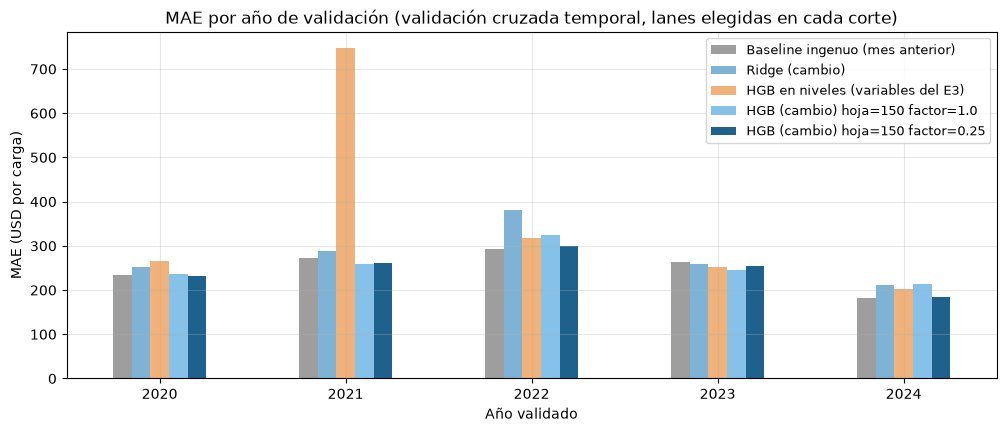

Años en los que el modelo seleccionado le gana al baseline ingenuo: ['2020', '2021', '2023']


modelo,Baseline ingenuo (mes anterior),Ridge (cambio),HGB en niveles (variables del E3),HGB (cambio) hoja=150 factor=1.0,HGB (cambio) hoja=150 factor=0.25
anio_validado,,,,,
2020,235.00,253.00,266.00,237.00,233.00
2021,271.00,289.00,746.00,260.00,262.00
2022,293.00,381.00,318.00,325.00,299.00
2023,263.00,260.00,253.00,246.00,255.00
2024,182.00,212.00,203.00,214.00,185.00


In [16]:
por_fold = resultados_cv.pivot(index="anio_validado", columns="modelo", values="MAE")
mostrar = ["Baseline ingenuo (mes anterior)", "Ridge (cambio)", "HGB en niveles (variables del E3)", sin_amortiguar, mejor]
por_fold[mostrar].plot.bar(figsize=(12, 4.5), color=["#9e9e9e", "#7fb3d5", "#f0b27a", "#85c1e9", "#1f618d"], rot=0)
plt.title("MAE por año de validación (validación cruzada temporal, lanes elegidas en cada corte)")
plt.ylabel("MAE (USD por carga)")
plt.xlabel("Año validado")
plt.legend(fontsize=9)
plt.show()

ganador_fold = por_fold[mejor] < por_fold["Baseline ingenuo (mes anterior)"]
print("Años en los que el modelo seleccionado le gana al baseline ingenuo:", list(por_fold.index[ganador_fold]))
por_fold[mostrar].round(0)

**Interpretación.** Con la selección de lanes corregida, la validación cruzada muestra que el baseline ingenuo es todavía más difícil de vencer de lo que pensábamos, con un MAE promedio de 249 USD por carga. El Gradient Boosting que predice el cambio completo (factor 1) queda **peor** que el baseline (256), y solo cuando amortiguamos su cambio predicho logra quedar ligeramente por debajo. El modelo seleccionado es el de "min_samples_leaf" = 150 con factor 0.25, con un MAE de 247 (0.9% menos que el baseline) y un RMSE de 409 contra 418 (2.0% menos). Las diferencias entre los valores de hoja son muy pequeñas, por lo que el resultado depende mucho más del factor que de ese parámetro.

La comparación de control sigue siendo clara: el mismo algoritmo entrenado en niveles con las variables del E3 tiene un MAE promedio de 357 y en 2021 se dispara a 746, ya que ese año las tarifas subieron a niveles que no existían en el entrenamiento, lo cual justifica haber cambiado el target al cambio porcentual. La regresión Ridge (279) también queda peor que el baseline.

Por año, el modelo seleccionado le gana al baseline en 2020 (233 contra 235), 2021 (262 contra 271) y 2023 (255 contra 263), y pierde por poco en 2022 (299 contra 293) y 2024 (185 contra 182). En otras palabras, la ventaja es pequeña y no aparece todos los años, lo cual es una diferencia importante contra la versión anterior de este entregable, donde con las 94 lanes elegidas con información de 2026 el modelo parecía ganar por 3.8% en la validación cruzada; buena parte de esa ventaja venía del sesgo de selección y no del modelo.

Con el modelo ya seleccionado lo entrenamos una sola vez con todo el conjunto de desarrollo de las lanes elegibles en diciembre de 2024 (2000 a 2024).

In [17]:
modelo_final = crear_modelo_hgb(MEJOR_HOJA)
modelo_final.fit(desarrollo[ENTRADAS], desarrollo[TARGET])
print(f"Entrenado con {len(desarrollo):,} lane-meses de {desarrollo['lane'].nunique()} lanes, "
      f"de {desarrollo['mes'].min()} a {desarrollo['mes'].max()} | factor de amortiguamiento: {MEJOR_FACTOR}")

Entrenado con 22,535 lane-meses de 151 lanes, de 2000-02 a 2024-12 | factor de amortiguamiento: 0.25


## 8. Evaluación final en el conjunto de prueba

Esta es la única vez que se usa el conjunto de prueba (enero de 2025 a octubre de 2026), con las lanes elegibles en diciembre de 2024. Reportamos las siguientes métricas, todas en las mismas filas para el modelo y las referencias:

| Métrica | Qué significa en este problema |
|---|---|
| **MAE** | Cuántos USD por carga se equivoca el pronóstico en promedio; es la métrica principal porque se lee directo en dinero |
| **RMSE** | Igual que el MAE pero castiga más los errores grandes, que son los que más afectan un presupuesto |
| **WAPE** | Error total dividido entre el gasto total real; dice qué porcentaje del gasto en flete se pronosticó mal y permite comparar lanes cortas y largas |
| **R²** | Proporción de la variación explicada; la calculamos en USD y también sobre el cambio mensual, que es lo que realmente predice el modelo |
| **Sesgo** | Promedio de pronóstico menos real; si es negativo, el pronóstico se queda corto |

In [18]:
cambio_pred = modelo_final.predict(prueba[ENTRADAS])
pred_modelo = a_tarifa(prueba, cambio_pred, MEJOR_FACTOR)
pred_ingenuo = baseline_ingenuo(prueba)
pred_estacional = baseline_estacional(prueba)
pred_media = baseline_media(desarrollo, prueba)
real = prueba["tarifa"].to_numpy()

tabla_prueba = pd.DataFrame({
    "HGB (cambio), modelo seleccionado": metricas(real, pred_modelo),
    "Baseline ingenuo (mes anterior)": metricas(real, pred_ingenuo),
    "Baseline estacional (hace 12 meses)": metricas(real, pred_estacional),
    "Baseline media de entrenamiento": metricas(real, pred_media),
}).T
tabla_prueba["Sesgo (pred - real)"] = [np.mean(p - real) for p in [pred_modelo, pred_ingenuo, pred_estacional, pred_media]]
tabla_prueba

,MAE,RMSE,WAPE,R2,Sesgo (pred - real)
"HGB (cambio), modelo seleccionado",294.76,492.47,0.05,0.97,-66.90
Baseline ingenuo (mes anterior),299.35,503.54,0.06,0.96,-72.84
Baseline estacional (hace 12 meses),631.83,"1,053.81",0.12,0.84,-420.76
Baseline media de entrenamiento,"2,347.13","2,876.40",0.44,-0.16,"-1,062.12"


In [19]:
mejora_mae = 1 - tabla_prueba.loc["HGB (cambio), modelo seleccionado", "MAE"] / tabla_prueba.loc["Baseline ingenuo (mes anterior)", "MAE"]
mejora_rmse = 1 - tabla_prueba.loc["HGB (cambio), modelo seleccionado", "RMSE"] / tabla_prueba.loc["Baseline ingenuo (mes anterior)", "RMSE"]
print(f"Mejora contra el baseline ingenuo: MAE {mejora_mae:.1%} | RMSE {mejora_rmse:.1%}")

# R² sobre el cambio: mide cuánto del movimiento mensual explica el modelo (el baseline predice cambio 0)
cambio_real = prueba[TARGET].to_numpy()
print(f"R² sobre el cambio mensual: modelo {r2_score(cambio_real, MEJOR_FACTOR * cambio_pred):.3f} "
      f"| baseline {r2_score(cambio_real, np.zeros(len(prueba))):.3f}")

Mejora contra el baseline ingenuo: MAE 1.5% | RMSE 2.2%
R² sobre el cambio mensual: modelo 0.030 | baseline -0.015


**Interpretación.** En la prueba el modelo tiene un MAE de 295 USD por carga contra 299 del baseline ingenuo, es decir, se equivoca 1.5% menos, y un RMSE de 492 contra 504 (2.2% menos), con un WAPE de 5.5% del gasto real contra 5.6% del baseline. El baseline estacional (632) y la media de entrenamiento (2,347) quedan muy lejos, lo que confirma que la historia reciente de cada lane es la información más valiosa. La mejora es del mismo tamaño que la de la validación cruzada (0.9% en MAE y 2.0% en RMSE), lo cual es una buena señal de que el resultado no depende del periodo de prueba, aunque también confirma que es una mejora pequeña.

El R² en USD es de 0.97 para el modelo y para el baseline, pero este valor es engañoso porque casi toda la variación entre renglones viene de que unas lanes son mucho más caras que otras, algo que cualquier pronóstico que parta del mes anterior ya resuelve. Por eso también medimos el R² sobre el cambio mensual: el modelo explica solo alrededor de 3% de cuánto sube o baja la tarifa de un mes a otro, y el baseline queda ligeramente por debajo de cero, ya que siempre predice que no habrá cambio. Adicionalmente, los dos pronósticos tienen sesgo negativo (el modelo -67 USD y el baseline -73 USD por carga), es decir, en un periodo de alzas ambos tienden a quedarse cortos.

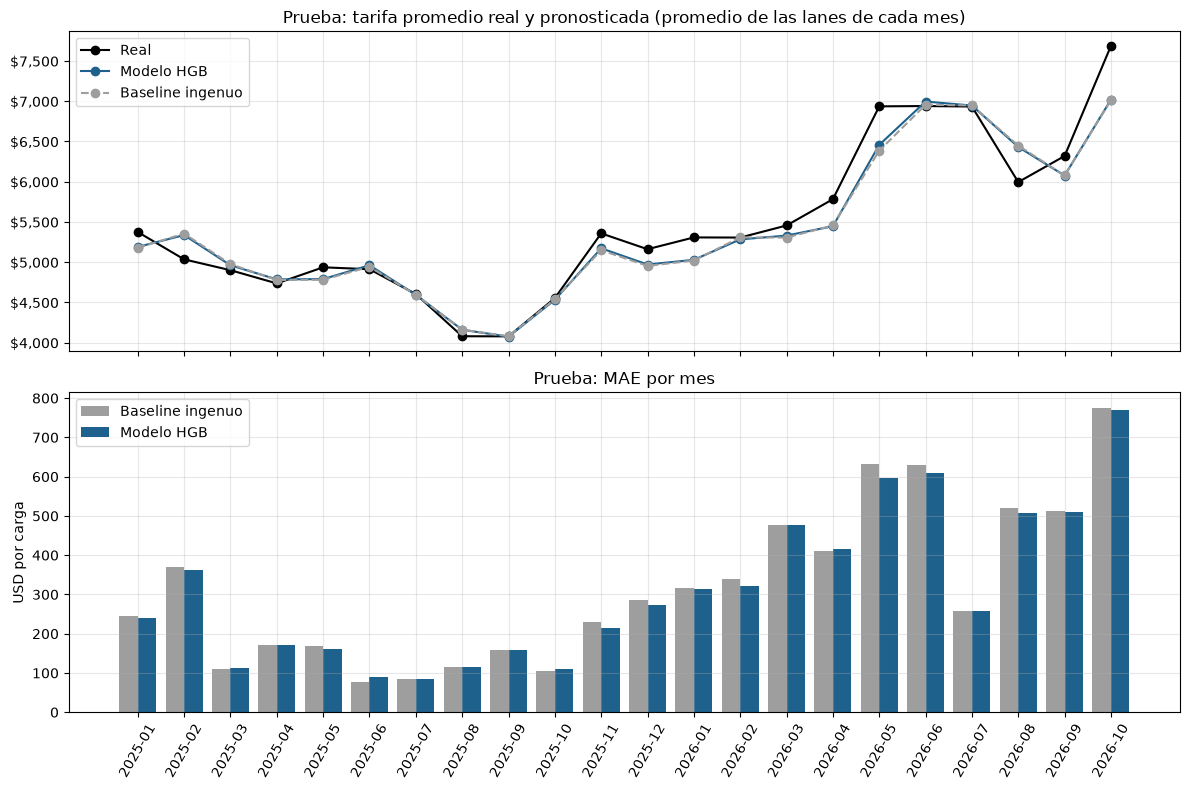

Meses en que el modelo tiene menor MAE que el baseline: 15 de 22


In [20]:
resultados = prueba[["lane", "origin", "destination", "mes", "distancia", "tarifa_lag1", "tarifa"]].copy()
resultados["pred_modelo"] = pred_modelo
resultados["pred_ingenuo"] = pred_ingenuo
resultados["error_modelo"] = (resultados["pred_modelo"] - resultados["tarifa"]).abs()
resultados["error_ingenuo"] = (resultados["pred_ingenuo"] - resultados["tarifa"]).abs()

por_mes = resultados.groupby("mes").agg(real=("tarifa", "mean"), modelo=("pred_modelo", "mean"), ingenuo=("pred_ingenuo", "mean"),
                                        mae_modelo=("error_modelo", "mean"), mae_ingenuo=("error_ingenuo", "mean"))
etiquetas = por_mes.index.astype(str)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(etiquetas, por_mes["real"], marker="o", color="black", label="Real")
axes[0].plot(etiquetas, por_mes["modelo"], marker="o", color="#1f618d", label="Modelo HGB")
axes[0].plot(etiquetas, por_mes["ingenuo"], marker="o", color="#9e9e9e", linestyle="--", label="Baseline ingenuo")
axes[0].set_title("Prueba: tarifa promedio real y pronosticada (promedio de las lanes de cada mes)")
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
axes[0].legend()

x = np.arange(len(por_mes))
axes[1].bar(x - 0.2, por_mes["mae_ingenuo"], width=0.4, color="#9e9e9e", label="Baseline ingenuo")
axes[1].bar(x + 0.2, por_mes["mae_modelo"], width=0.4, color="#1f618d", label="Modelo HGB")
axes[1].set_title("Prueba: MAE por mes")
axes[1].set_ylabel("USD por carga")
axes[1].legend()
plt.xticks(x, etiquetas, rotation=60)
plt.tight_layout()
plt.show()

print(f"Meses en que el modelo tiene menor MAE que el baseline: {(por_mes['mae_modelo'] < por_mes['mae_ingenuo']).sum()} de {len(por_mes)}")

**Interpretación.** En la gráfica superior las líneas del modelo y del baseline casi se enciman, lo cual es lo esperado con un factor de 0.25, ya que el modelo solo mueve un poco el pronóstico del mes anterior. En la gráfica inferior el modelo tiene menor MAE en 15 de los 22 meses, y sus mejores meses son los de alza, como mayo de 2026 (597 contra 632), febrero de 2026 (321 contra 339) y noviembre de 2025 (214 contra 230). Por otro lado, pierde por poco en meses tranquilos como junio de 2025 (91 contra 78) y octubre de 2025 (111 contra 105), y ninguno de los dos anticipa la subida de octubre de 2026, donde la tarifa promedio de las lanes reportadas subió cerca de 10% y los dos se equivocaron por más de 770 USD por carga.

In [21]:
# ¿Dónde funciona mejor o peor? Según el tamaño del cambio real del mes
resultados["cambio_real"] = np.log(resultados["tarifa"] / resultados["tarifa_lag1"])
resultados["tipo_mes"] = pd.cut(resultados["cambio_real"], bins=[-np.inf, -0.05, -0.0001, 0.0001, 0.05, np.inf],
                                labels=["baja > 5%", "baja 0 a 5%", "sin cambio", "sube 0 a 5%", "sube > 5%"])
por_tipo = resultados.groupby("tipo_mes", observed=True).agg(lane_meses=("tarifa", "size"),
                                                             mae_modelo=("error_modelo", "mean"),
                                                             mae_ingenuo=("error_ingenuo", "mean"))
por_tipo["diferencia"] = por_tipo["mae_modelo"] - por_tipo["mae_ingenuo"]

# Y según la distancia de la lane
resultados["distancia_grupo"] = pd.cut(resultados["distancia"], bins=[0, 700, 1400, 2000, np.inf],
                                       labels=["< 700 mi", "700 a 1,400 mi", "1,400 a 2,000 mi", "> 2,000 mi"])
por_distancia = resultados.groupby("distancia_grupo", observed=True).agg(lane_meses=("tarifa", "size"),
                                                                         tarifa_promedio=("tarifa", "mean"),
                                                                         mae_modelo=("error_modelo", "mean"),
                                                                         mae_ingenuo=("error_ingenuo", "mean"))
por_distancia["WAPE_modelo"] = por_distancia["mae_modelo"] / por_distancia["tarifa_promedio"]
por_distancia["WAPE_ingenuo"] = por_distancia["mae_ingenuo"] / por_distancia["tarifa_promedio"]
display(por_tipo)
display(por_distancia)

,lane_meses,mae_modelo,mae_ingenuo,diferencia
tipo_mes,,,,
baja > 5%,204,535.04,542.73,-7.69
baja 0 a 5%,169,153.34,145.71,7.63
sin cambio,346,7.21,0.00,7.21
sube 0 a 5%,203,139.91,147.78,-7.88
sube > 5%,273,682.34,704.70,-22.36


,lane_meses,tarifa_promedio,mae_modelo,mae_ingenuo,WAPE_modelo,WAPE_ingenuo
distancia_grupo,,,,,,
< 700 mi,190,"1,876.54",104.65,105.39,0.06,0.06
"700 a 1,400 mi",237,"3,317.56",289.38,297.37,0.09,0.09
"1,400 a 2,000 mi",255,"5,044.36",314.10,316.91,0.06,0.06
"> 2,000 mi",513,"7,828.92",358.04,363.38,0.05,0.05


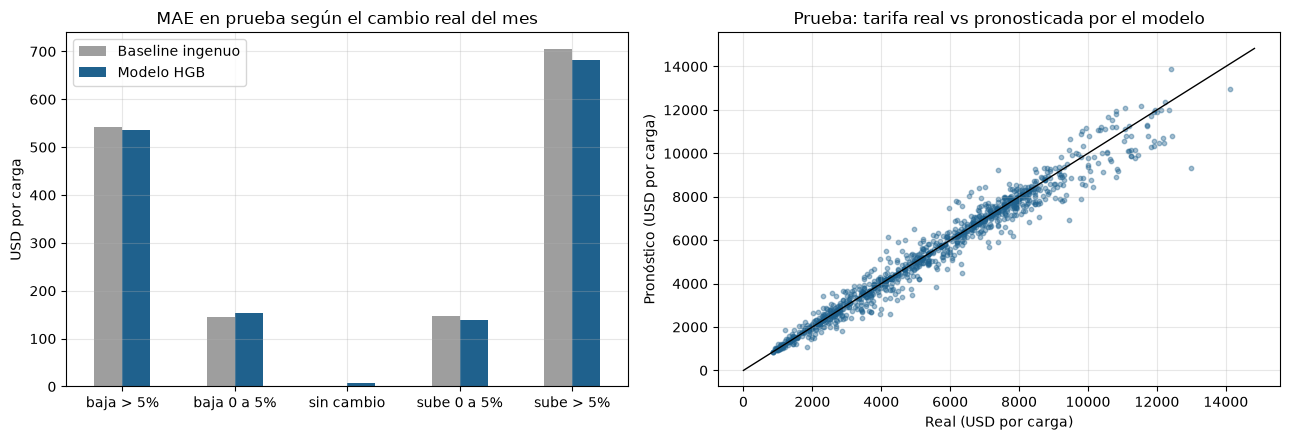

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
por_tipo[["mae_ingenuo", "mae_modelo"]].plot.bar(ax=axes[0], color=["#9e9e9e", "#1f618d"], rot=0)
axes[0].set_title("MAE en prueba según el cambio real del mes")
axes[0].set_ylabel("USD por carga")
axes[0].set_xlabel("")
axes[0].legend(["Baseline ingenuo", "Modelo HGB"])

axes[1].scatter(resultados["tarifa"], resultados["pred_modelo"], s=10, alpha=0.4, color="#1f618d")
limite = [0, resultados[["tarifa", "pred_modelo"]].max().max() * 1.05]
axes[1].plot(limite, limite, color="black", linewidth=1)
axes[1].set_title("Prueba: tarifa real vs pronosticada por el modelo")
axes[1].set_xlabel("Real (USD por carga)")
axes[1].set_ylabel("Pronóstico (USD por carga)")
plt.tight_layout()
plt.show()

**Interpretación.** Las tablas y la gráfica de la izquierda muestran dónde aporta el modelo. En los meses con movimientos de más de 5% el modelo reduce el error, sobre todo en las alzas (de 705 a 682 USD), y en los cambios pequeños las diferencias son de alrededor de 8 USD hacia un lado u otro. En los meses en que la tarifa no cambia, que en esta prueba son 346 casos (29%), el baseline acierta exacto por definición y el modelo se equivoca en promedio solo 7 USD, mucho menos que antes de amortiguar. En otras palabras, el factor hace que el modelo casi no pierda en meses tranquilos, a cambio de ganar poco en los meses de movimiento.

Por distancia, el modelo es igual o ligeramente mejor que el baseline en los cuatro grupos, y las lanes de 700 a 1,400 millas siguen siendo las de mayor error relativo (WAPE de 9% contra 5% en las lanes de más de 2,000 millas). La gráfica de la derecha muestra que los pronósticos se concentran alrededor de la diagonal y que los puntos que más se alejan están por debajo de ella en las tarifas altas, lo cual coincide con el sesgo negativo en meses de alza.

Como uno de los usos del pronóstico es decidir si conviene amarrar un contrato, revisamos también si el modelo anticipa la dirección del movimiento.

In [23]:
# Dirección del cambio en los meses con movimiento importante (más de 3%): ¿el modelo anticipa hacia dónde va la tarifa?
movimiento = resultados[resultados["cambio_real"].abs() > 0.03].copy()
movimiento["cambio_predicho"] = np.log(movimiento["pred_modelo"] / movimiento["tarifa_lag1"])
acierto = (np.sign(movimiento["cambio_predicho"]) == np.sign(movimiento["cambio_real"])).mean()
print(f"Lane-meses con movimiento mayor a 3%: {len(movimiento):,} ({len(movimiento) / len(resultados):.0%} de la prueba)")
print(f"El modelo acierta la dirección (sube o baja) en el {acierto:.0%} de esos casos; el baseline siempre predice 'sin cambio'")
print(f"Tamaño promedio del cambio real: {movimiento['cambio_real'].abs().mean():.1%} | del cambio predicho: {movimiento['cambio_predicho'].abs().mean():.1%}")

Lane-meses con movimiento mayor a 3%: 613 (51% de la prueba)
El modelo acierta la dirección (sube o baja) en el 65% de esos casos; el baseline siempre predice 'sin cambio'
Tamaño promedio del cambio real: 10.8% | del cambio predicho: 0.4%


**Interpretación.** En los 613 lane-meses con movimientos de más de 3% (51% de la prueba) el modelo acierta si la tarifa va a subir o bajar en 65% de los casos, algo que el baseline no puede hacer porque siempre predice que no habrá cambio. Sin embargo, el tamaño de los cambios que pronostica es muy pequeño (0.4% en promedio contra 10.8% de los cambios reales), ya que el factor de 0.25 reduce a la cuarta parte lo que propone el modelo. Por lo tanto, consideramos que el modelo sirve más como una señal de dirección (por ejemplo, "esta lane probablemente suba el próximo mes") que como una estimación de cuánto va a subir.

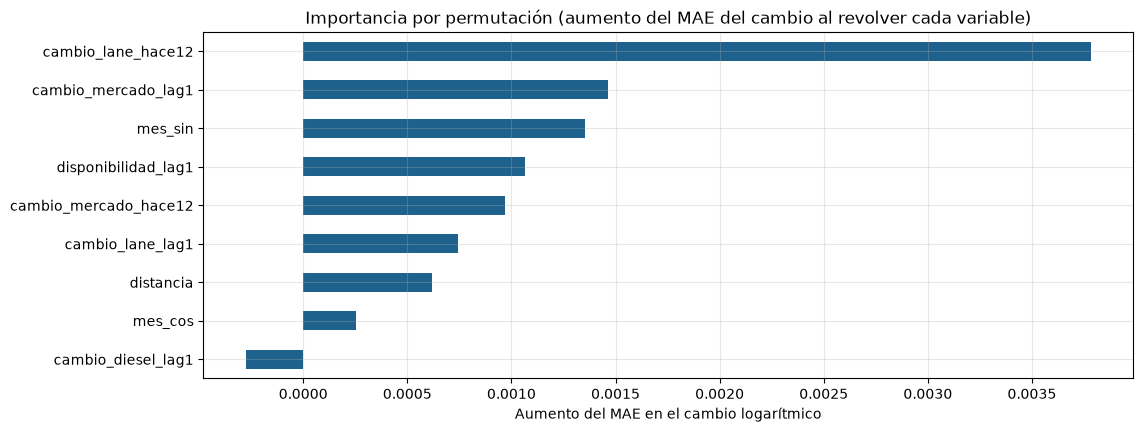

In [24]:
# Importancia de variables por permutación (se calcula después de la evaluación, solo para interpretar)
importancia = permutation_importance(modelo_final, prueba[ENTRADAS], prueba[TARGET], scoring="neg_mean_absolute_error",
                                     n_repeats=10, random_state=SEMILLA)
importancia = pd.Series(importancia.importances_mean, index=ENTRADAS).sort_values()

importancia.plot.barh(color="#1f618d")
plt.title("Importancia por permutación (aumento del MAE del cambio al revolver cada variable)")
plt.xlabel("Aumento del MAE en el cambio logarítmico")
plt.show()

**Interpretación.** La importancia por permutación mide cuánto empeora el error del modelo si revolvemos al azar una variable, y la calculamos después de la evaluación solo para interpretar, sin usarla para tomar decisiones. La variable más importante es "cambio_lane_hace12", es decir, lo que hizo la misma lane en la misma época del año pasado, seguida de "cambio_mercado_lag1", que indica si todo el mercado viene subiendo, de la estacionalidad del calendario ("mes_sin") y de la disponibilidad de camiones. Esto tiene sentido con el EDA, donde encontramos una estacionalidad moderada pero constante. Por otro lado, "cambio_diesel_lag1" vuelve a tener importancia ligeramente negativa, lo que coincide con el E3, donde el diésel casi no se movía con la tarifa mes contra mes (correlación de 0.09), y es un candidato a quitar en una siguiente versión, aunque esa decisión tendría que tomarse con la validación cruzada y no con la prueba.

## 9. Comparación, interpretación y utilidad para el negocio

Para saber si la mejora de 1.5% es real o podría ser suerte, calculamos un intervalo de confianza con **bootstrap por mes**: tomamos al azar, con reemplazo, 22 meses de la prueba, recalculamos la mejora y repetimos 2,000 veces. Remuestreamos meses completos y no renglones, porque las lanes de un mismo mes se mueven juntas y tratarlas como independientes daría un intervalo falsamente angosto.

In [25]:
# Intervalo de confianza de la mejora con bootstrap por mes: se remuestrean MESES completos con reemplazo
rng = np.random.default_rng(SEMILLA)
errores_mes = resultados.groupby("mes").agg(suma_modelo=("error_modelo", "sum"), suma_ingenuo=("error_ingenuo", "sum"),
                                            n=("tarifa", "size"))
mejoras = []
for _ in range(2000):
    muestra = errores_mes.iloc[rng.integers(0, len(errores_mes), len(errores_mes))]
    mejoras.append(1 - muestra["suma_modelo"].sum() / muestra["suma_ingenuo"].sum())
inferior, superior = np.percentile(mejoras, [2.5, 97.5])
print(f"Mejora del MAE contra el baseline: {mejora_mae:.1%} (intervalo de 95%: {inferior:.1%} a {superior:.1%})")
print(f"Proporción de remuestreos en que el modelo es mejor: {np.mean(np.array(mejoras) > 0):.1%}")

Mejora del MAE contra el baseline: 1.5% (intervalo de 95%: 0.3% a 2.6%)
Proporción de remuestreos en que el modelo es mejor: 98.7%


In [26]:
# Traducción a dinero: supongamos un distribuidor que mueve 200 cargas spot al mes en estas lanes
CARGAS_MES = 200
mae_modelo = tabla_prueba.loc["HGB (cambio), modelo seleccionado", "MAE"]
mae_ingenuo = tabla_prueba.loc["Baseline ingenuo (mes anterior)", "MAE"]
print(f"Error absoluto esperado del presupuesto mensual (si los errores no se compensan): "
      f"modelo ${mae_modelo * CARGAS_MES:,.0f} | baseline ${mae_ingenuo * CARGAS_MES:,.0f}")
print(f"Diferencia: ${(mae_ingenuo - mae_modelo) * CARGAS_MES:,.0f} al mes, ${(mae_ingenuo - mae_modelo) * CARGAS_MES * 12:,.0f} al año")

Error absoluto esperado del presupuesto mensual (si los errores no se compensan): modelo $58,952 | baseline $59,871
Diferencia: $919 al mes, $11,026 al año


**Interpretación.** El intervalo de 95% para la mejora del MAE va de 0.3% a 2.6% y el modelo es mejor en 98.7% de los remuestreos, por lo que la mejora parece consistente, pero es muy pequeña. El intervalo es angosto precisamente porque el factor de 0.25 hace que el modelo se parezca mucho al baseline, de modo que los dos se equivocan casi igual en cada mes. Además, en la validación cruzada el modelo perdió por poco en 2 de los 5 años, así que consideramos que lo más honesto es decir que el modelo **empata o mejora ligeramente** al baseline, y no que lo supera con claridad.

En términos de negocio, si el distribuidor mueve 200 cargas spot al mes en estas lanes, el error absoluto de su presupuesto de flete sería de alrededor de 59,000 USD al mes con el modelo contra 59,900 con el baseline, una diferencia de cerca de 900 USD al mes u 11,000 al año. Este cálculo supone que los errores no se compensan entre lanes, así que es una cota superior y sirve más para dimensionar que como ahorro garantizado, y con una diferencia de este tamaño probablemente no justificaría por sí sola el costo de mantener el modelo.

Los errores tienen consecuencias distintas: cuando el pronóstico se queda corto (sesgo de -67 USD por carga) el presupuesto queda por debajo del gasto real, lo cual es el error más costoso en meses de alza, mientras que cuando sobreestima en un mes tranquilo la empresa podría amarrar un contrato que no necesitaba. Por lo tanto, consideramos que el valor del modelo está más en la señal de dirección (65% de acierto en los movimientos de más de 3%) que en la reducción del error, y que para el presupuesto el baseline del mes anterior con un margen de seguridad en los meses de alza sigue siendo una opción muy razonable.

## 10. Ejemplos de predicción y proyección a futuro

### 10.1 Predicciones sobre el conjunto de prueba (con valor real conocido)
Para no escoger los ejemplos a mano, tomamos tres registros de prueba según el error del modelo: uno donde acierta (percentil 10), uno típico (percentil 50) y uno donde falla (percentil 90), entre las lanes que siguen activas en el último mes.

In [27]:
# Regla para elegir sin "escoger a mano": entre las lanes activas en el último mes, tomamos el registro de prueba
# cuyo error del modelo está en el percentil 10 (acierta), 50 (caso típico) y 90 (falla)
activas = base.loc[base["mes"] == ULTIMO_MES, "lane"]
candidatas = resultados[resultados["lane"].isin(activas)].sort_values("error_modelo").reset_index(drop=True)
posiciones = [int(p * (len(candidatas) - 1)) for p in [0.10, 0.50, 0.90]]
ejemplos = candidatas.iloc[posiciones].assign(caso=["acierta (p10)", "típico (p50)", "falla (p90)"])

tabla_ejemplos = ejemplos[["caso", "lane", "mes", "distancia", "tarifa_lag1", "pred_ingenuo", "pred_modelo", "tarifa"]].copy()
tabla_ejemplos["cambio_predicho"] = tabla_ejemplos["pred_modelo"] / tabla_ejemplos["tarifa_lag1"] - 1
tabla_ejemplos["cambio_real"] = tabla_ejemplos["tarifa"] / tabla_ejemplos["tarifa_lag1"] - 1
tabla_ejemplos["error_modelo"] = tabla_ejemplos["pred_modelo"] - tabla_ejemplos["tarifa"]
tabla_ejemplos["error_ingenuo"] = tabla_ejemplos["pred_ingenuo"] - tabla_ejemplos["tarifa"]
tabla_ejemplos.style.format({"distancia": "{:,.0f}", "tarifa_lag1": "${:,.0f}", "pred_ingenuo": "${:,.0f}", "pred_modelo": "${:,.0f}",
                             "tarifa": "${:,.0f}", "cambio_predicho": "{:+.1%}", "cambio_real": "{:+.1%}",
                             "error_modelo": "{:+,.0f}", "error_ingenuo": "{:+,.0f}"}).hide(axis="index")

caso,lane,mes,distancia,tarifa_lag1,pred_ingenuo,pred_modelo,tarifa,cambio_predicho,cambio_real,error_modelo,error_ingenuo
acierta (p10),"MEXICO CROSSINGS THROUGH NOGALES, ARIZONA → LOS ANGELES",2025-07,560,"$1,425","$1,425","$1,425","$1,450",+0.0%,+1.8%,-25,-25
típico (p50),"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGTON → MIAMI",2025-05,"3,225","$7,200","$7,200","$7,179","$7,400",-0.3%,+2.8%,-221,-200
falla (p90),"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGTON → CHICAGO",2025-02,"2,000","$5,525","$5,525","$5,512","$4,600",-0.2%,-16.7%,+912,+925


**Interpretación.** Los tres ejemplos muestran lo cerca que está el modelo del baseline. En el caso donde acierta (Mexico Crossings Through Nogales → Los Angeles, julio de 2025) el modelo no esperaba cambio, la tarifa subió 1.8% y los dos se equivocaron por 25 USD. En el caso típico (Yakima Valley → Miami, mayo de 2025) el modelo esperaba una baja de 0.3% y la tarifa subió 2.8%, por lo que se equivocó por 221 USD, un poco más que el baseline (200 USD). En el caso donde falla (Yakima Valley → Chicago, febrero de 2025) la tarifa bajó casi 17% en un mes; el modelo sí anticipó la dirección, pero con una baja de solo 0.2%, y se equivocó por 912 USD contra 925 del baseline, lo que muestra que ninguno de los dos está hecho para anticipar choques de esta magnitud.

### 10.2 Proyección para noviembre de 2026 (sin valor real todavía)
Estas cifras **no** se usan para medir el desempeño, ya que todavía no existe la tarifa real de noviembre. Para producir la proyección usamos el corte de octubre de 2026, que da exactamente las 94 lanes del E3, agregamos una fila futura para las que tienen dato en octubre, calculamos sus variables con la misma función de la sección 3 y reentrenamos el modelo con toda la historia de esas lanes, usando la misma hoja y el mismo factor elegidos en la validación cruzada, ya que en la práctica siempre se usaría la información más reciente.

In [28]:
# 1) Corte de producción: octubre de 2026. Las lanes elegibles hoy son las 94 del E3
lanes_hoy = lanes_elegibles(base, ULTIMO_MES)
base_hoy = base[base["lane"].isin(lanes_hoy)]

# 2) Filas futuras: noviembre de 2026 para las lanes con dato en el último mes. La tarifa queda vacía porque no la conocemos
MES_FUTURO = ULTIMO_MES + 1
lanes_activas = base_hoy[base_hoy["mes"] == ULTIMO_MES][["origin", "destination", "lane", "distancia"]]
futuro = lanes_activas.assign(mes=MES_FUTURO, tarifa=np.nan, disponibilidad=np.nan)

# 3) Mismas variables, calculadas con exactamente la misma función
panel_futuro = crear_variables(pd.concat([base_hoy, futuro], ignore_index=True), diesel_mensual)
historia_hoy = panel_futuro.dropna(subset=["tarifa", "tarifa_lag1"])
filas_futuras = panel_futuro[panel_futuro["mes"] == MES_FUTURO].reset_index(drop=True)

# 4) Para producción se reentrena con TODA la historia disponible y la misma configuración (hoja y factor)
modelo_produccion = crear_modelo_hgb(MEJOR_HOJA).fit(historia_hoy[ENTRADAS], historia_hoy[TARGET])
filas_futuras["pronostico"] = a_tarifa(filas_futuras, modelo_produccion.predict(filas_futuras[ENTRADAS]), MEJOR_FACTOR)
filas_futuras["cambio_pronosticado"] = filas_futuras["pronostico"] / filas_futuras["tarifa_lag1"] - 1

proyeccion = filas_futuras[filas_futuras["lane"].isin(ejemplos["lane"])][["lane", "mes", "tarifa_lag1", "pronostico", "cambio_pronosticado"]]
proyeccion = proyeccion.rename(columns={"tarifa_lag1": f"tarifa real {ULTIMO_MES}", "pronostico": f"estimación {MES_FUTURO} (sin valor real)"})
print(f"Lanes elegibles en el corte {ULTIMO_MES}: {len(lanes_hoy)} | con dato en {ULTIMO_MES}: {len(filas_futuras)}")
print(f"Proyección para {MES_FUTURO}: cambio promedio pronosticado {filas_futuras['cambio_pronosticado'].mean():+.1%}")
proyeccion.style.format({f"tarifa real {ULTIMO_MES}": "${:,.0f}", f"estimación {MES_FUTURO} (sin valor real)": "${:,.0f}",
                         "cambio_pronosticado": "{:+.1%}"}).hide(axis="index")

Lanes elegibles en el corte 2026-10: 94 | con dato en 2026-10: 70
Proyección para 2026-11: cambio promedio pronosticado +1.2%


lane,mes,tarifa real 2026-10,estimación 2026-11 (sin valor real),cambio_pronosticado
"MEXICO CROSSINGS THROUGH NOGALES, ARIZONA → LOS ANGELES",2026-11,"$1,700","$1,704",+0.2%
"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGTON → CHICAGO",2026-11,"$8,575","$8,688",+1.3%
"YAKIMA VALLEY AND WENATCHEE DISTRICT, WASHINGTON → MIAMI",2026-11,"$14,125","$14,265",+1.0%


In [29]:
resultados.drop(columns=["tipo_mes", "distancia_grupo"]).assign(mes=resultados["mes"].astype(str)).to_csv(
    f"{CARPETA_PROC}/predicciones_prueba.csv", index=False)
filas_futuras[["lane", "mes", "tarifa_lag1", "pronostico", "cambio_pronosticado"]].assign(mes=MES_FUTURO.strftime("%Y-%m")).to_csv(
    f"{CARPETA_PROC}/proyeccion_{MES_FUTURO}.csv", index=False)
print("Archivos guardados en", CARPETA_PROC)

Archivos guardados en data/processed


**Interpretación.** Para noviembre de 2026 el modelo proyecta un aumento promedio de 1.2% en las 70 lanes con dato en octubre, y para las tres lanes de los ejemplos alzas de entre 0.2% y 1.3%. Hay que leer estas cifras con cuidado, ya que vienen justo después de la fuerte subida de octubre y, como vimos, el modelo amortiguado pronostica cambios mucho más pequeños que los reales, por lo que conviene leerlas como "la tarifa probablemente siga subiendo un poco" y no como el tamaño esperado del movimiento. Las proyecciones de todas las lanes se guardan en "data/processed", junto con las predicciones del conjunto de prueba, para que se puedan comparar cuando USDA publique los datos reales.

## 11. Conclusiones técnicas

**Qué logramos.** Construimos un prototipo de pronóstico mensual por lane con una metodología que respeta el orden del tiempo en todos sus pasos: la lista de lanes se elige en cada corte solo con la información disponible, el pipeline se ajusta solo con entrenamiento, la validación cruzada es temporal por meses y la prueba se usa una sola vez. Con esta metodología el modelo seleccionado (Gradient Boosting que predice el cambio, con hoja de 150 y factor de 0.25) mejora ligeramente al baseline del mes anterior: en la prueba el MAE bajó de 299 a 295 USD por carga (1.5%) y el RMSE de 504 a 492 (2.2%), con un intervalo de 95% para la mejora de 0.3% a 2.6%, y supera con amplitud al baseline del mismo mes del año previo (632). También comprobamos que predecir el cambio porcentual en lugar de la tarifa fue una decisión clave, ya que el mismo algoritmo en niveles fue mucho peor que el baseline.

**Qué aprendimos de la corrección.** La versión anterior de este entregable reportaba una mejora de 5.5% en la prueba, pero usaba las 94 lanes elegidas con información de 2026. Al elegir las lanes en cada corte la mejora bajó a 1.5%, lo que indica que buena parte de la ventaja anterior venía del sesgo de supervivencia y no del modelo. Consideramos que este es el hallazgo más importante del entregable, ya que la cifra corregida es la que realmente se habría obtenido al usar el modelo en su momento.

**Qué no quedó resuelto.** El modelo no anticipa los choques grandes (como la subida de cerca de 10% de octubre de 2026), pronostica cambios mucho más pequeños que los reales y en la validación cruzada perdió por poco en 2022 y 2024. Además, seguimos trabajando con tarifas de mercado publicadas por USDA y no con lo que paga la empresa, por lo que la comparación entre spot y contrato y el ahorro real todavía requieren datos internos.

**Límites de confianza.** Con una mejora de este tamaño, lo más honesto es decir que el modelo empata o mejora ligeramente al baseline. Por eso lo vemos como una señal de apoyo, principalmente de dirección, y no como un reemplazo del criterio del área de compras, y los resultados aplican a lanes con al menos 36 meses de historia y actividad reciente, no a lanes nuevas.

**Qué mejoraríamos con más tiempo o más datos.** Primero, agregar variables que anticipen choques, como volúmenes de embarque de USDA o índices de capacidad del mercado, ya que con la información actual el baseline captura casi todo lo que se puede predecir. Segundo, dar intervalos de predicción (por ejemplo con regresión por cuantiles) en lugar de un solo número, para que el presupuesto incluya un rango. Tercero, replantear el problema como clasificación de la dirección del movimiento, que es donde el modelo muestra más valor. Por último, con datos internos de la empresa podríamos medir el ahorro real de decidir entre spot y contrato con base en el pronóstico.

## 12. Referencias

- U.S. Department of Agriculture, Agricultural Marketing Service. (2026). *Refrigerated Truck Rates and Availability* [Conjunto de datos; copia descargada con datos al 27 de octubre de 2026]. AgTransport. https://agtransport.usda.gov/d/acar-e3r8
- U.S. Energy Information Administration. (2026). *Weekly U.S. No 2 Diesel Retail Prices* [Conjunto de datos]. https://www.eia.gov/dnav/pet/hist/LeafHandler.ashx?n=PET&s=EMD_EPD2D_PTE_NUS_DPG&f=W
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3a ed.). OTexts. https://otexts.com/fpp3/